# Ringkasan Pilot & Rekomendasi — Klasifikasi ASD vs TD (ABIDE I, sMRI T1w + fenotipik)

> **Ini hasil PILOT pada sampel ±20 % dataset (200 dari 1.002 subjek), bukan hasil akhir.**
> Sampel diambil hanya dari 853 subjek *development* (stratifikasi site × label × fold, seed 42); 149 subjek *test held-out*
> tidak disentuh. Tujuan pilot: memastikan pipeline benar & bebas kebocoran, memilih kandidat model, lalu mengunci konfigurasi
> sebelum dijalankan pada data penuh.

Semua angka dibaca langsung dari hasil runner/notebook 06 (`report/`); tidak ada model yang dilatih di notebook ini.
Metrik: **BA** = balanced accuracy, **F1m** = F1 macro, **AUC** = ROC-AUC; pooled out-of-fold test 5 fold, 95 % CI bootstrap 2000×.
Batas acak: BA = 0,5 dan AUC = 0,5.

In [1]:
from pathlib import Path
RESULT_DIR = Path(r"C:\ta_local\results\pilot200_v2")   # sama dengan notebook 06

In [2]:
import json, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pilot_common.py").exists())
T = RESULT_DIR / "report" / "tables"
assert T.exists(), "Jalankan notebook 06 dulu (report/tables belum ada)"
val = json.loads((RESULT_DIR / "report" / "run_validation.json").read_text(encoding="utf-8"))
LOCK = json.loads((RESULT_DIR / "locked_config_kandidat.json").read_text(encoding="utf-8"))
M = pd.read_csv(T / "06_metrik_pooled_ci.csv").set_index("eksperimen")
folds = pd.read_csv(PROJECT / "data" / "folds.csv")
kohort = pd.read_csv(T / "02_kohort.csv").set_index("grup")
site = pd.read_csv(T / "13_site_learning.csv")
youden = pd.read_csv(T / "12b_threshold_youden.csv")
bnfix = pd.read_csv(T / "12b_bugfix_bn.csv") if (T / "12b_bugfix_bn.csv").exists() else None
cause = pd.read_csv(T / "12a_penyebab_kegagalan_citra.csv")
unit_img = pd.read_csv(T / "05_unit_citra.csv")

def num(s):   # "0.584 [0.512, 0.652]" -> (0.584, 0.512, 0.652)
    a = [float(x) for x in re.findall(r"-?\d+\.\d+", str(s))]
    return tuple(a[:3]) if len(a) >= 3 else (np.nan,) * 3
def f2(x): return f"{x:.2f}".replace(".", ",")
def ci(e, k): v = num(M.at[e, f"{k} [95% CI]"]); return f"{f2(v[0])} [{f2(v[1])}–{f2(v[2])}]"

STYLE = [{"selector": "th", "props": "background:#1c5cab;color:white;text-align:left;padding:6px 8px;font-size:12px"},
         {"selector": "td", "props": "padding:6px 8px;font-size:12px;vertical-align:top;border-bottom:1px solid #e5e5e5"},
         {"selector": "table", "props": "border-collapse:collapse;width:100%"}]
def show(df, title=None, wrap=()):
    if title: display(Markdown(f"#### {title}"))
    st = df.style.hide(axis="index").set_table_styles(STYLE)
    for c in wrap: st = st.set_properties(subset=[c], **{"white-space": "normal", "min-width": "260px"})
    display(st)

n_dev = int((folds.split == "dev").sum()); n_all = len(folds); n_test = int((folds.split == "test").sum())
n_pilot = int(kohort.at["Semua", "n"])
print(f"Pilot: {n_pilot} dari {n_all} subjek ({100 * n_pilot / n_all:.1f} %) | dev {n_dev} | test held-out {n_test} | status run: {val['status']}")

Pilot: 200 dari 1002 subjek (20.0 %) | dev 853 | test held-out 149 | status run: complete


## 1. Konteks eksperimen

In [3]:
ctx = pd.DataFrame([
    ("Dataset", f"ABIDE I, {n_all} subjek setelah cleaning (20 site); T1w sMRI + fenotipik"),
    ("Sampel pilot", f"{n_pilot} subjek = {100 * n_pilot / n_all:.0f} % dataset ({100 * n_pilot / n_dev:.0f} % subjek dev): "
                     f"{int(kohort.at['ASD', 'n'])} ASD / {int(kohort.at['TD', 'n'])} TD, {int(kohort.at['Semua', 'n site'])} site"),
    ("Data yang tidak disentuh", f"{n_test} subjek test held-out (dipakai sekali di akhir) + {n_dev - n_pilot} subjek dev sisa (sedang dipreprocessing)"),
    ("Preprocessing", "N4 → skull stripping HD-BET → registrasi afin ANTs ke MNI152 → 2 mm, 96×112×96 → z-score (deterministik, QC per subjek)"),
    ("Validasi", "5-fold CV terstratifikasi site × label; inner validation 20 % per fold untuk seleksi; tanpa kebocoran (diaudit otomatis)"),
    ("Modalitas", "Fenotipik (usia, jenis kelamin, FIQ, volume otak) · ROI atlas Harvard-Oxford (± ComBat) · citra 2.5D (15 slice) · citra 3D · fusion"),
    ("Model", "LogReg, XGBoost, MLP, TabM · EfficientNet-B0, ResNet18, ConvNeXt V2 (pretrained) · DINOv2 & SFCN (beku) · CNN 2D/3D dari nol"),
    ("Aturan anti-bias", "Seleksi model dari inner validation (bukan test); threshold 0,5 tetap (+ Youden dari inner val); SITE_ID & skor klinis tidak dipakai sebagai fitur"),
], columns=["Aspek", "Keterangan"])
show(ctx, wrap=["Keterangan"])

Aspek,Keterangan
Dataset,"ABIDE I, 1002 subjek setelah cleaning (20 site); T1w sMRI + fenotipik"
Sampel pilot,"200 subjek = 20 % dataset (23 % subjek dev): 95 ASD / 105 TD, 20 site"
Data yang tidak disentuh,149 subjek test held-out (dipakai sekali di akhir) + 653 subjek dev sisa (sedang dipreprocessing)
Preprocessing,"N4 → skull stripping HD-BET → registrasi afin ANTs ke MNI152 → 2 mm, 96×112×96 → z-score (deterministik, QC per subjek)"
Validasi,5-fold CV terstratifikasi site × label; inner validation 20 % per fold untuk seleksi; tanpa kebocoran (diaudit otomatis)
Modalitas,"Fenotipik (usia, jenis kelamin, FIQ, volume otak) · ROI atlas Harvard-Oxford (± ComBat) · citra 2.5D (15 slice) · citra 3D · fusion"
Model,"LogReg, XGBoost, MLP, TabM · EfficientNet-B0, ResNet18, ConvNeXt V2 (pretrained) · DINOv2 & SFCN (beku) · CNN 2D/3D dari nol"
Aturan anti-bias,"Seleksi model dari inner validation (bukan test); threshold 0,5 tetap (+ Youden dari inner val); SITE_ID & skor klinis tidak dipakai sebagai fitur"


## 2. Dataset yang digunakan

**ABIDE I** (Autism Brain Imaging Data Exchange I): data multi-site dari 17 institusi (20 site setelah pemecahan per protokol),
berisi citra MRI struktural T1-weighted dan data fenotipik (diagnosis, usia, jenis kelamin, IQ, dll.). Label: `DX_GROUP`
1 = ASD (autism spectrum disorder), 2 = TD (typically developing). Tabel pertama menunjukkan jumlah subjek di tiap tahap
seleksi; tabel kedua demografi per partisi, termasuk sampel pilot ±20 % yang dipakai pada laporan ini.

In [4]:
ph = pd.read_csv(PROJECT / "dataset" / "fenotipik" / "Phenotypic_V1_0b.csv")
ms = pd.read_csv(PROJECT / "dataset" / "merge_dataset" / "master_dataset.csv")
cm = pd.read_csv(PROJECT / "dataset" / "cleaned_dataset" / "cleaned_master_dataset.csv")
cl = pd.read_csv(PROJECT / "dataset" / "cleaned_dataset" / "cleaning_log.csv")
sub = pd.read_csv(PROJECT / "data" / "subset_20pct.csv")
def asd_td(s): return f"{int((s == 1).sum())} / {int((s == 2).sum())}"
drop = cl[cl.action == "DROPPED"]
n_noimg = int((drop.step == "01_merge").sum()); n_qc = int((drop.step != "01_merge").sum())
excl = pd.read_csv(PROJECT / "data" / "exclusions.csv")
lab01 = folds.label.map({1: 1, 0: 2})
funnel = pd.DataFrame([
    ("CSV fenotipik ABIDE I", len(ph), asd_td(ph.DX_GROUP), "File resmi Phenotypic_V1_0b (notebook 01)"),
    ("Punya citra T1w (merge)", len(ms), asd_td(ms.DX_GROUP), f"−{n_noimg} subjek tanpa file T1w (inner join, notebook 03)"),
    ("Lolos cleaning & QC", len(cm), asd_td(cm.DX_GROUP), f"−{n_qc} subjek gagal QC kualitas citra PCP (gerak kepala, noise, kepala terpotong; notebook 04)"),
    ("Lolos audit (dataset final)", len(folds), asd_td(lab01), f"−{len(excl)} subjek: citra identik tertaut ke 2 ID dengan fenotipik berbeda (notebook 05a)"),
    ("  • development (dev)", int((folds.split == 'dev').sum()), asd_td(lab01[folds.split == 'dev']), "Untuk pelatihan & validasi silang 5 fold"),
    ("  • test held-out", int((folds.split == 'test').sum()), asd_td(lab01[folds.split == 'test']), "Disimpan, dipakai SEKALI di akhir"),
    ("Sampel PILOT (laporan ini)", len(sub), asd_td(lab01[folds.SUB_ID.isin(sub.SUB_ID)]),
     f"±{100 * len(sub) / len(folds):.0f} % dataset, hanya dari dev; stratifikasi site × label × fold, seed 42"),
], columns=["Tahap", "Jumlah subjek", "ASD / TD", "Keterangan"])
show(funnel, "Alur jumlah subjek", wrap=["Keterangan"])

d = folds.merge(cm[["SUB_ID", "AGE_AT_SCAN", "SEX", "FIQ"]], on="SUB_ID", how="left")
def demo(g, name):
    return {"Partisi": name, "n": len(g), "ASD / TD": f"{int(g.label.sum())} / {int((1 - g.label).sum())}",
            "% ASD": f"{100 * g.label.mean():.0f} %", "Site": g.SITE_ID.nunique(),
            "Usia (median [min–maks])": f"{g.AGE_AT_SCAN.median():.1f} [{g.AGE_AT_SCAN.min():.1f}–{g.AGE_AT_SCAN.max():.1f}] th",
            "Laki-laki": f"{100 * (g.SEX == 1).mean():.0f} %", "FIQ (mean ± SD)": f"{g.FIQ.mean():.0f} ± {g.FIQ.std():.0f}",
            "FIQ tersedia": f"{100 * g.FIQ.notna().mean():.0f} %"}
demo_t = pd.DataFrame([demo(d, "Dataset final"), demo(d[d.split == "dev"], "Development"), demo(d[d.split == "test"], "Test held-out"),
                       demo(d[d.SUB_ID.isin(sub.SUB_ID)], "Pilot (±20 %)")])
show(demo_t, "Demografi per partisi")
display(Markdown("Fitur fenotipik yang dipakai model: **usia, jenis kelamin, FIQ, volume otak** (dari mask). Skor diagnostik "
                 "(ADOS, ADI-R, SRS, dll.) dan SITE_ID **tidak** dipakai sebagai fitur untuk mencegah kebocoran label/site."))

#### Alur jumlah subjek

Tahap,Jumlah subjek,ASD / TD,Keterangan
CSV fenotipik ABIDE I,1112,539 / 573,File resmi Phenotypic_V1_0b (notebook 01)
Punya citra T1w (merge),1102,531 / 571,"−10 subjek tanpa file T1w (inner join, notebook 03)"
Lolos cleaning & QC,1004,469 / 0,"−98 subjek gagal QC kualitas citra PCP (gerak kepala, noise, kepala terpotong; notebook 04)"
Lolos audit (dataset final),1002,467 / 535,−2 subjek: citra identik tertaut ke 2 ID dengan fenotipik berbeda (notebook 05a)
• development (dev),853,398 / 455,Untuk pelatihan & validasi silang 5 fold
• test held-out,149,69 / 80,"Disimpan, dipakai SEKALI di akhir"
Sampel PILOT (laporan ini),200,95 / 105,"±20 % dataset, hanya dari dev; stratifikasi site × label × fold, seed 42"


#### Demografi per partisi

Partisi,n,ASD / TD,% ASD,Site,Usia (median [min–maks]),Laki-laki,FIQ (mean ± SD),FIQ tersedia
Dataset final,1002,467 / 535,47 %,20,15.0 [6.5–64.0] th,84 %,109 ± 15,93 %
Development,853,398 / 455,47 %,20,15.0 [6.5–64.0] th,85 %,109 ± 15,93 %
Test held-out,149,69 / 80,46 %,20,14.7 [8.5–52.0] th,83 %,110 ± 15,93 %
Pilot (±20 %),200,95 / 105,48 %,20,14.9 [6.5–46.0] th,86 %,109 ± 16,94 %


Fitur fenotipik yang dipakai model: **usia, jenis kelamin, FIQ, volume otak** (dari mask). Skor diagnostik (ADOS, ADI-R, SRS, dll.) dan SITE_ID **tidak** dipakai sebagai fitur untuk mencegah kebocoran label/site.

## 3. Tahapan yang sudah dilakukan

In [5]:
stages = pd.DataFrame([
    ("01", "EDA fenotipik", "Inspeksi CSV fenotipik, distribusi diagnosis/usia/IQ per site, nilai -9999 sebagai missing", "Tabel & grafik EDA", "Selesai"),
    ("02", "EDA sMRI", "Inspeksi header & intensitas NIfTI T1w (dimensi, ukuran voxel, orientasi)", "Ringkasan header", "Selesai"),
    ("03", "Merge data", "Pencocokan SUB_ID fenotipik ↔ citra (inner join), validasi header", "master_dataset.csv (1.102)", "Selesai"),
    ("04", "Cleaning & QC", "Penanganan missing, QC kualitas citra (rating PCP, FOV, anisotropi), log tiap keputusan", "cleaned_master_dataset.csv (1.004)", "Selesai"),
    ("05a", "Audit & split", "Audit duplikat/kebocoran, split test held-out 149, 5 fold stratifikasi site × label, subset pilot 20 %",
     "folds.csv, subset_20pct.csv", "Selesai"),
    ("05b", "Preprocessing fenotipik", "Imputasi & scaling di-fit hanya pada train tiap fold (anti-leakage)", "src/pheno_preprocessing.py", "Selesai"),
    ("05c", "Preprocessing sMRI", "N4 → skull stripping HD-BET → registrasi afin ke MNI152 → 2 mm → z-score; deterministik + QC",
     f"Volume 96×112×96: pilot {n_pilot} ✓, sisa {n_all - n_pilot} dijadwalkan malam", "Pilot selesai, sisa berjalan"),
    ("06", "Modeling pilot v1 & v2", "Fenotipik, ROI ± ComBat, CNN 2.5D/3D (pretrained, foundation, dari nol), fusion & ensemble; "
     "seleksi via inner validation", "168 unit model × fold", "Selesai"),
    ("06", "Sanity check & perbaikan", "Overfit test (bug BatchNorm ditemukan & diperbaiki), cek kewajaran SFCN, threshold Youden",
     "sanity/, rerun bugfix", "Selesai"),
    ("06", "Laporan & audit", "Audit kebocoran otomatis, metrik + CI bootstrap, confusion matrix, ROC, efek site, reload checkpoint",
     "06_modeling_report.html", "Selesai"),
    ("—", "Konfigurasi dikunci", "Kandidat model, fusion, threshold, bugfix dikunci sebelum data penuh", "locked_config_kandidat.json", "Selesai"),
    ("next", "Data penuh & test akhir", "Modeling 853 dev dengan konfigurasi terkunci, lalu evaluasi sekali pada 149 test held-out", "—", "Belum"),
], columns=["Notebook", "Tahap", "Yang dilakukan", "Output", "Status"])
st = stages.style.hide(axis="index").set_table_styles(STYLE).set_properties(subset=["Yang dilakukan"], **{"white-space": "normal", "min-width": "320px"}) \
    .map(lambda v: "background:#d9f2e6" if v == "Selesai" else ("background:#fff4d6" if v != "" and v in ("Belum", "Pilot selesai, sisa berjalan") else ""), subset=["Status"])
display(st)

Notebook,Tahap,Yang dilakukan,Output,Status
01,EDA fenotipik,"Inspeksi CSV fenotipik, distribusi diagnosis/usia/IQ per site, nilai -9999 sebagai missing",Tabel & grafik EDA,Selesai
02,EDA sMRI,"Inspeksi header & intensitas NIfTI T1w (dimensi, ukuran voxel, orientasi)",Ringkasan header,Selesai
03,Merge data,"Pencocokan SUB_ID fenotipik ↔ citra (inner join), validasi header",master_dataset.csv (1.102),Selesai
04,Cleaning & QC,"Penanganan missing, QC kualitas citra (rating PCP, FOV, anisotropi), log tiap keputusan",cleaned_master_dataset.csv (1.004),Selesai
05a,Audit & split,"Audit duplikat/kebocoran, split test held-out 149, 5 fold stratifikasi site × label, subset pilot 20 %","folds.csv, subset_20pct.csv",Selesai
05b,Preprocessing fenotipik,Imputasi & scaling di-fit hanya pada train tiap fold (anti-leakage),src/pheno_preprocessing.py,Selesai
05c,Preprocessing sMRI,N4 → skull stripping HD-BET → registrasi afin ke MNI152 → 2 mm → z-score; deterministik + QC,"Volume 96×112×96: pilot 200 ✓, sisa 802 dijadwalkan malam","Pilot selesai, sisa berjalan"
06,Modeling pilot v1 & v2,"Fenotipik, ROI ± ComBat, CNN 2.5D/3D (pretrained, foundation, dari nol), fusion & ensemble; seleksi via inner validation",168 unit model × fold,Selesai
06,Sanity check & perbaikan,"Overfit test (bug BatchNorm ditemukan & diperbaiki), cek kewajaran SFCN, threshold Youden","sanity/, rerun bugfix",Selesai
06,Laporan & audit,"Audit kebocoran otomatis, metrik + CI bootstrap, confusion matrix, ROC, efek site, reload checkpoint",06_modeling_report.html,Selesai


## 4. Flowchart pipeline

Kotak biru = sudah dikerjakan; kotak bergaris putus = tahap berikutnya.

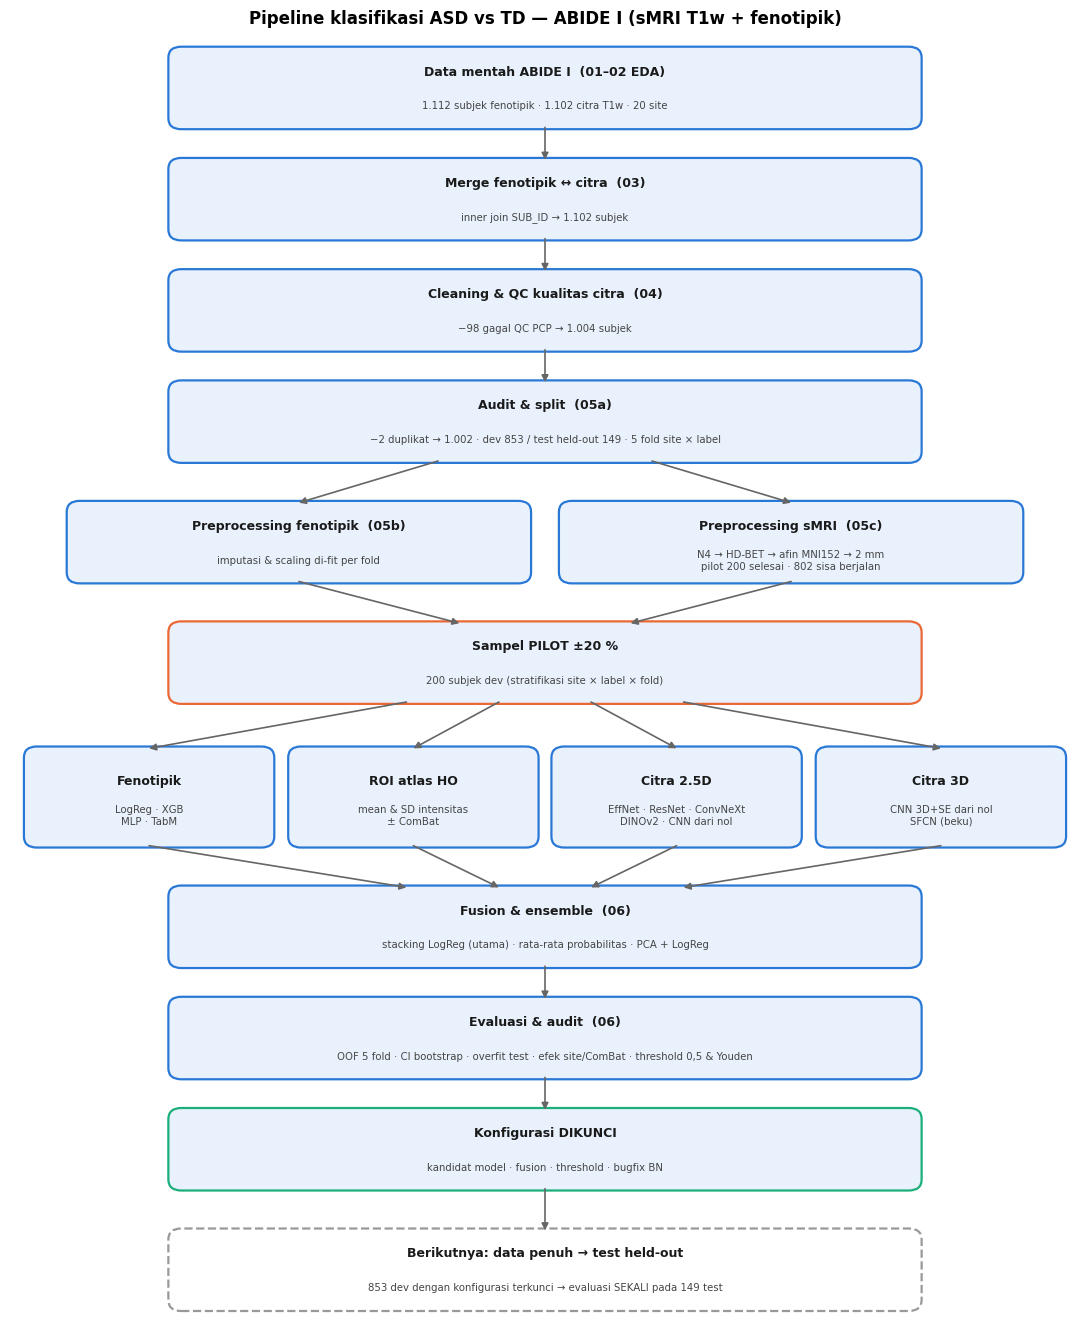

In [6]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11, 13.5)); ax.set_xlim(0, 10); ax.set_ylim(0, 14); ax.axis("off")
def box(x, y, w, h, title, sub, done=True, color="#2a78d6"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc="#e8f1fc" if done else "white", ec=color if done else "#999", lw=1.6, ls="-" if done else "--"))
    ax.text(x, y + 0.17, title, ha="center", va="center", fontsize=9, fontweight="bold", color="#1a1a1a")
    ax.text(x, y - 0.2, sub, ha="center", va="center", fontsize=7.3, color="#444", linespacing=1.25)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#666", lw=1.2, shrinkA=0, shrinkB=0))
H = 0.85
box(5, 13.4, 7, H, "Data mentah ABIDE I  (01–02 EDA)", f"{len(ph):,} subjek fenotipik · {len(ms) + n_noimg - n_noimg:,} citra T1w · 20 site".replace(",", "."))
box(5, 12.2, 7, H, "Merge fenotipik ↔ citra  (03)", f"inner join SUB_ID → {len(ms):,} subjek".replace(",", "."))
box(5, 11.0, 7, H, "Cleaning & QC kualitas citra  (04)", f"−{n_qc} gagal QC PCP → {len(cm):,} subjek".replace(",", "."))
box(5, 9.8, 7, H, "Audit & split  (05a)", f"−{len(excl)} duplikat → {len(folds):,} · dev {n_dev} / test held-out {n_test} · 5 fold site × label".replace(",", "."))
box(2.7, 8.5, 4.3, H, "Preprocessing fenotipik  (05b)", "imputasi & scaling di-fit per fold")
box(7.3, 8.5, 4.3, H, "Preprocessing sMRI  (05c)", f"N4 → HD-BET → afin MNI152 → 2 mm\npilot {n_pilot} selesai · {n_all - n_pilot} sisa berjalan")
box(5, 7.2, 7, H, "Sampel PILOT ±20 %", f"{n_pilot} subjek dev (stratifikasi site × label × fold)", color="#eb6834")
xs = [1.3, 3.77, 6.23, 8.7]
for x, (t, s_) in zip(xs, [("Fenotipik", "LogReg · XGB\nMLP · TabM"), ("ROI atlas HO", "mean & SD intensitas\n± ComBat"),
                           ("Citra 2.5D", "EffNet · ResNet · ConvNeXt\nDINOv2 · CNN dari nol"), ("Citra 3D", "CNN 3D+SE dari nol\nSFCN (beku)")]):
    box(x, 5.75, 2.3, 1.05, t, s_)
box(5, 4.35, 7, H, "Fusion & ensemble  (06)", "stacking LogReg (utama) · rata-rata probabilitas · PCA + LogReg")
box(5, 3.15, 7, H, "Evaluasi & audit  (06)", "OOF 5 fold · CI bootstrap · overfit test · efek site/ComBat · threshold 0,5 & Youden")
box(5, 1.95, 7, H, "Konfigurasi DIKUNCI", "kandidat model · fusion · threshold · bugfix BN", color="#1baf7a")
box(5, 0.65, 7, H, "Berikutnya: data penuh → test held-out", f"{n_dev} dev dengan konfigurasi terkunci → evaluasi SEKALI pada {n_test} test", done=False)
for y1, y2 in [(13.4, 12.2), (12.2, 11.0), (11.0, 9.8)]: arrow(5, y1 - H / 2, 5, y2 + H / 2)
arrow(4.0, 9.8 - H / 2, 2.7, 8.5 + H / 2); arrow(6.0, 9.8 - H / 2, 7.3, 8.5 + H / 2)
arrow(2.7, 8.5 - H / 2, 4.2, 7.2 + H / 2); arrow(7.3, 8.5 - H / 2, 5.8, 7.2 + H / 2)
for x in xs: arrow(5 + (x - 5) * 0.35, 7.2 - H / 2, x, 5.75 + 0.525)
for x in xs: arrow(x, 5.75 - 0.525, 5 + (x - 5) * 0.35, 4.35 + H / 2)
for y1, y2 in [(4.35, 3.15), (3.15, 1.95), (1.95, 0.65)]: arrow(5, y1 - H / 2, 5, y2 + H / 2)
ax.set_title("Pipeline klasifikasi ASD vs TD — ABIDE I (sMRI T1w + fenotipik)", fontsize=12, fontweight="bold", pad=6)
fig.tight_layout(); fig.savefig(RESULT_DIR / "report" / "figures" / "07_flowchart.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Hasil utama per modalitas (balanced accuracy)

Satu baris per kandidat terkunci (dipilih dari inner validation) dan fusion. Kolom **di atas acak?** = batas bawah CI BA > 0,5.
Gambar di bawah tabel: titik = BA pooled, garis = 95 % CI.

Modalitas,Model,Peran,BA [95% CI],AUC [95% CI],F1 macro [95% CI],Sens / Spes,di atas acak?
Baseline,majority,Tebak kelas mayoritas,"0,50 [0,50–0,50]","0,50 [0,50–0,50]","0,34 [0,31–0,37]","0,00 / 1,00",—
Fenotipik,mlp_tab,terpilih inner val,"0,54 [0,47–0,61]","0,58 [0,49–0,65]","0,54 [0,47–0,61]","0,60 / 0,49",belum
Fenotipik,tabm,pembanding,"0,58 [0,51–0,65]","0,56 [0,47–0,64]","0,58 [0,51–0,65]","0,66 / 0,51",ya
Fenotipik,logreg,baseline standar,"0,56 [0,49–0,62]","0,56 [0,48–0,65]","0,56 [0,49–0,62]","0,53 / 0,59",belum
ROI (± ComBat),roi_tabm_cb,terpilih inner val,"0,52 [0,45–0,59]","0,56 [0,48–0,63]","0,52 [0,45–0,58]","0,55 / 0,49",belum
Citra 2.5D pretrained,resnet18,terpilih inner val,"0,52 [0,46–0,57]","0,49 [0,41–0,57]","0,48 [0,41–0,54]","0,22 / 0,81",belum
Citra 2.5D pretrained,effnet_b0,pembanding,"0,53 [0,47–0,60]","0,52 [0,44–0,60]","0,52 [0,45–0,59]","0,36 / 0,70",belum
Citra 2.5D dari nol,scratch2d,setelah bugfix BN,"0,52 [0,45–0,59]","0,52 [0,43–0,60]","0,52 [0,45–0,59]","0,44 / 0,59",belum
Citra 3D dari nol,scratch3d,setelah bugfix BN,"0,45 [0,39–0,52]","0,46 [0,38–0,54]","0,44 [0,38–0,51]","0,33 / 0,57",belum
Fusion fenotipik + ROI,PR · F1_stack_logreg,stacking (metode utama),"0,57 [0,49–0,64]","0,60 [0,52–0,68]","0,57 [0,49–0,64]","0,55 / 0,59",belum


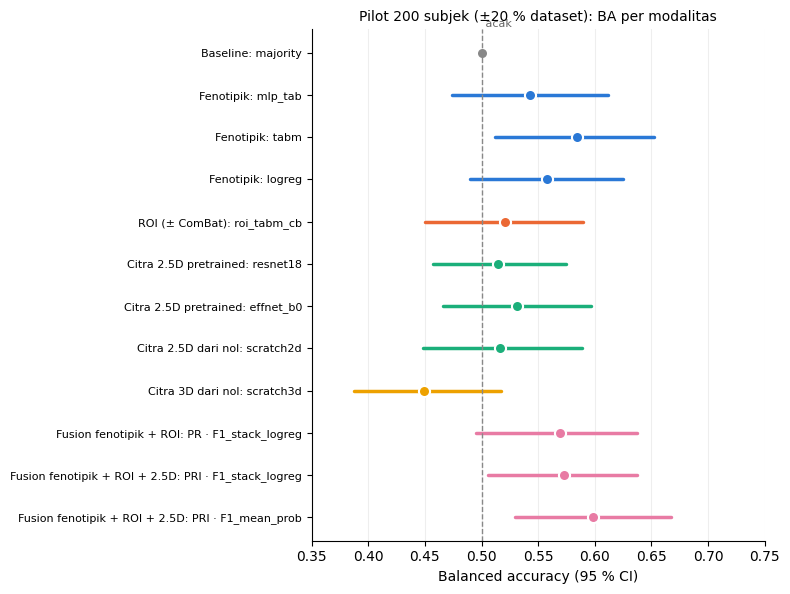

In [7]:
rows_spec = [("Baseline", "majority", "Tebak kelas mayoritas"),
             ("Fenotipik", LOCK["kandidat_data_penuh"]["pheno"][0], "terpilih inner val"),
             ("Fenotipik", "tabm", "pembanding"), ("Fenotipik", "logreg", "baseline standar"),
             ("ROI (± ComBat)", LOCK["kandidat_data_penuh"]["roi"][0], "terpilih inner val"),
             ("Citra 2.5D pretrained", LOCK["kandidat_data_penuh"]["img25d_pretrained"][0], "terpilih inner val"),
             ("Citra 2.5D pretrained", LOCK["kandidat_data_penuh"]["img25d_pretrained"][1], "pembanding"),
             ("Citra 2.5D dari nol", "scratch2d", "setelah bugfix BN" if bnfix is not None else "TIDAK VALID (bug BN) — menunggu rerun"),
             ("Citra 3D dari nol", "scratch3d", "setelah bugfix BN" if bnfix is not None else "TIDAK VALID (bug BN) — menunggu rerun"),
             ("Fusion fenotipik + ROI", "PR|F1_stack_logreg", "stacking (metode utama)"),
             ("Fusion fenotipik + ROI + 2.5D", "PRI|F1_stack_logreg", "stacking (metode utama)"),
             ("Fusion fenotipik + ROI + 2.5D", "PRI|F1_mean_prob", "rata-rata probabilitas (pembanding)")]
rows = []
for mod, e, note in rows_spec:
    if e not in M.index: continue
    ba = num(M.at[e, "BA [95% CI]"])
    rows.append({"Modalitas": mod, "Model": e.replace("|", " · "), "Peran": note, "BA [95% CI]": ci(e, "BA"),
                 "AUC [95% CI]": ci(e, "AUC"), "F1 macro [95% CI]": ci(e, "F1m"),
                 "Sens / Spes": f"{f2(num(M.at[e, 'Sens [95% CI]'])[0])} / {f2(num(M.at[e, 'Spes [95% CI]'])[0])}",
                 "di atas acak?": "ya" if ba[1] > 0.5 else ("—" if e == "majority" else "belum"), "_ba": ba})
R = pd.DataFrame(rows)
st = R.drop(columns="_ba").style.hide(axis="index").set_table_styles(STYLE).map(
    lambda v: "background:#d9f2e6;font-weight:bold" if v == "ya" else ("color:#888" if v == "belum" else ""), subset=["di atas acak?"])
display(st)

fig, ax = plt.subplots(figsize=(8, 0.42 * len(R) + 1))
y = np.arange(len(R))[::-1]
col = {"Baseline": "#888888", "Fenotipik": "#2a78d6", "ROI (± ComBat)": "#eb6834", "Citra 2.5D pretrained": "#1baf7a",
       "Citra 2.5D dari nol": "#1baf7a", "Citra 3D dari nol": "#eda100"}
for yi, r, b in zip(y, R.itertuples(), R["_ba"]):
    c = col.get(r.Modalitas, "#e87ba4")
    ax.plot([b[1], b[2]], [yi, yi], color=c, lw=2.5, solid_capstyle="round"); ax.plot(b[0], yi, "o", color=c, ms=8, mec="white", mew=1.5)
ax.axvline(0.5, color="#888", ls="--", lw=1); ax.text(0.5, len(R) - 0.4, " acak", color="#666", fontsize=8)
ax.set_yticks(y, [f"{r.Modalitas}: {r.Model}" for r in R.itertuples()], fontsize=8); ax.set_xlabel("Balanced accuracy (95 % CI)")
ax.set_xlim(0.35, 0.75); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#eee")
ax.set_title(f"Pilot {n_pilot} subjek (±20 % dataset): BA per modalitas", fontsize=10); fig.tight_layout(); plt.show()

## 6. Metrik lengkap: accuracy, F1 macro, dll.

Semua metrik pada threshold 0,5 (pooled out-of-fold 5 fold, n = 200). **Recall** = sensitivitas ASD; **spesifisitas** = recall TD;
**precision** = presisi kelas ASD. Warna sel: makin biru makin tinggi (skala 0,40–0,70). Tabel kedua memberi 95 % CI-nya.

#### Nilai metrik (pooled)

Modalitas,Model,Accuracy,Balanced acc.,Precision,Recall (sens.),Spesifisitas,F1 macro,ROC-AUC
Baseline,majority,0.525,0.500,0.000,0.000,1.000,0.344,0.500
Fenotipik,mlp_tab,0.540,0.543,0.514,0.600,0.486,0.540,0.576
Fenotipik,tabm,0.580,0.584,0.548,0.663,0.505,0.579,0.557
Fenotipik,logreg,0.560,0.558,0.538,0.526,0.590,0.558,0.564
ROI (± ComBat),roi_tabm_cb,0.520,0.521,0.495,0.547,0.495,0.520,0.556
Citra 2.5D pretrained,resnet18,0.530,0.515,0.512,0.221,0.810,0.476,0.489
Citra 2.5D pretrained,effnet_b0,0.540,0.531,0.523,0.358,0.705,0.521,0.522
Citra 2.5D dari nol,scratch2d,0.520,0.516,0.494,0.442,0.590,0.515,0.516
Citra 3D dari nol,scratch3d,0.455,0.449,0.408,0.326,0.571,0.443,0.461
Fusion fenotipik + ROI,PR · F1_stack_logreg,0.570,0.569,0.547,0.547,0.590,0.569,0.604


#### 95 % CI bootstrap

Modalitas,Model,Accuracy,Balanced acc.,Precision,Recall (sens.),Spesifisitas,F1 macro,ROC-AUC
Baseline,majority,"0,53 [0,46–0,59]","0,50 [0,50–0,50]","0,00 [0,00–0,00]","0,00 [0,00–0,00]","1,00 [1,00–1,00]","0,34 [0,31–0,37]","0,50 [0,50–0,50]"
Fenotipik,mlp_tab,"0,54 [0,47–0,61]","0,54 [0,47–0,61]","0,51 [0,42–0,61]","0,60 [0,49–0,69]","0,49 [0,39–0,58]","0,54 [0,47–0,61]","0,58 [0,49–0,65]"
Fenotipik,tabm,"0,58 [0,51–0,65]","0,58 [0,51–0,65]","0,55 [0,46–0,64]","0,66 [0,56–0,75]","0,51 [0,41–0,60]","0,58 [0,51–0,65]","0,56 [0,47–0,64]"
Fenotipik,logreg,"0,56 [0,49–0,62]","0,56 [0,49–0,62]","0,54 [0,43–0,64]","0,53 [0,42–0,62]","0,59 [0,50–0,68]","0,56 [0,49–0,62]","0,56 [0,48–0,65]"
ROI (± ComBat),roi_tabm_cb,"0,52 [0,45–0,59]","0,52 [0,45–0,59]","0,49 [0,40–0,59]","0,55 [0,45–0,65]","0,49 [0,40–0,59]","0,52 [0,45–0,58]","0,56 [0,48–0,63]"
Citra 2.5D pretrained,resnet18,"0,53 [0,46–0,60]","0,52 [0,46–0,57]","0,51 [0,35–0,67]","0,22 [0,14–0,31]","0,81 [0,73–0,88]","0,48 [0,41–0,54]","0,49 [0,41–0,57]"
Citra 2.5D pretrained,effnet_b0,"0,54 [0,47–0,61]","0,53 [0,47–0,60]","0,52 [0,40–0,65]","0,36 [0,26–0,46]","0,70 [0,61–0,79]","0,52 [0,45–0,59]","0,52 [0,44–0,60]"
Citra 2.5D dari nol,scratch2d,"0,52 [0,45–0,59]","0,52 [0,45–0,59]","0,49 [0,39–0,60]","0,44 [0,34–0,55]","0,59 [0,49–0,69]","0,52 [0,45–0,59]","0,52 [0,43–0,60]"
Citra 3D dari nol,scratch3d,"0,46 [0,39–0,53]","0,45 [0,39–0,52]","0,41 [0,30–0,52]","0,33 [0,24–0,42]","0,57 [0,48–0,66]","0,44 [0,38–0,51]","0,46 [0,38–0,54]"
Fusion fenotipik + ROI,PR · F1_stack_logreg,"0,57 [0,49–0,64]","0,57 [0,49–0,64]","0,55 [0,44–0,65]","0,55 [0,45–0,65]","0,59 [0,49–0,68]","0,57 [0,49–0,64]","0,60 [0,52–0,68]"


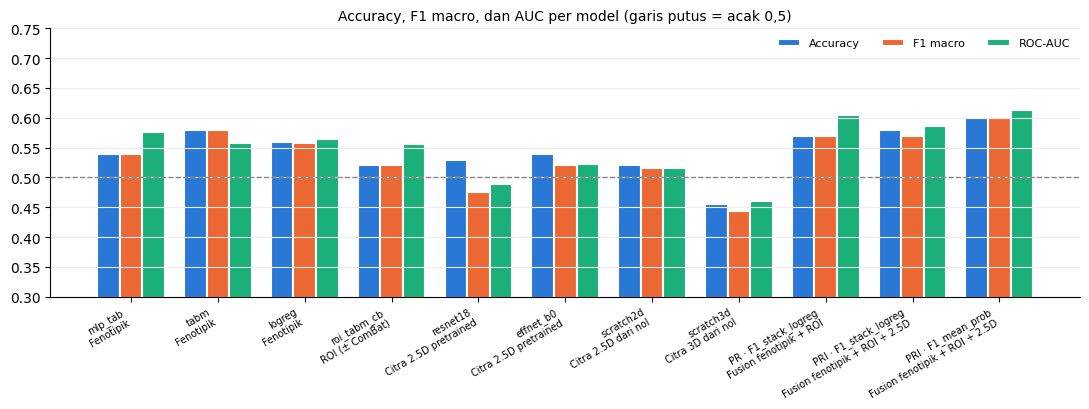

In [8]:
KM = [("Accuracy", "Acc"), ("Balanced acc.", "BA"), ("Precision", "Prec"), ("Recall (sens.)", "Sens"), ("Spesifisitas", "Spes"),
      ("F1 macro", "F1m"), ("ROC-AUC", "AUC")]
pts, cis = [], []
for mod, e, note in rows_spec:
    if e not in M.index: continue
    base_ = {"Modalitas": mod, "Model": e.replace("|", " · ")}
    pts.append({**base_, **{lbl: num(M.at[e, f"{k} [95% CI]"])[0] for lbl, k in KM}})
    cis.append({**base_, **{lbl: ci(e, k) for lbl, k in KM}})
P = pd.DataFrame(pts)
st = P.style.hide(axis="index").set_table_styles(STYLE).format({lbl: "{:.3f}" for lbl, _ in KM}) \
    .background_gradient(cmap="Blues", vmin=0.40, vmax=0.70, subset=[lbl for lbl, _ in KM])
display(Markdown("#### Nilai metrik (pooled)")); display(st)
show(pd.DataFrame(cis), "95 % CI bootstrap")

sel = P[P.Modalitas != "Baseline"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.2)); w = 0.26; x = np.arange(len(sel))
for i, (lbl, c) in enumerate([("Accuracy", "#2a78d6"), ("F1 macro", "#eb6834"), ("ROC-AUC", "#1baf7a")]):
    ax.bar(x + (i - 1) * w, sel[lbl], w, color=c, label=lbl, edgecolor="white", linewidth=1.5)
ax.axhline(0.5, color="#888", ls="--", lw=1); ax.set_ylim(0.3, 0.75); ax.set_xticks(x, [f"{m}\n{mo}" for m, mo in zip(sel.Model, sel.Modalitas)],
                                                                                        fontsize=7, rotation=30, ha="right")
ax.legend(fontsize=8, ncol=3, frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#eee")
ax.set_title("Accuracy, F1 macro, dan AUC per model (garis putus = acak 0,5)", fontsize=10); fig.tight_layout()
fig.savefig(RESULT_DIR / "report" / "figures" / "07_metrik_lengkap.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Insight utama

In [9]:
def rng(names, k="BA"):
    v = [num(M.at[n, f"{k} [95% CI]"])[0] for n in names if n in M.index]
    return f"{f2(min(v))}–{f2(max(v))}"
pheno = ["logreg", "xgb", "mlp_tab", "tabm"]; roi = [n for n in M.index if n.startswith("roi_")]
img = [n for n in M.index if M.at[n, "modalitas"] in ("img25d", "img3d") and "lama" not in n]
learned = ", ".join(f"{m} {s}" for m, s in zip(unit_img.model, unit_img["sudah belajar"]) if "/" in str(s) and "lama" not in m)
above = [e for e in M.index if not e.startswith("embcb_") and e != "majority" and num(M.at[e, "BA [95% CI]"])[1] > 0.5]
y_down = sum(num(d)[0] < 0 for d in youden["ΔBA [95% CI]"].dropna())
ins = [
    ("Sinyal ASD vs TD ada, tetapi lemah",
     f"Hanya {len(above)} dari {sum(1 for e in M.index if not e.startswith('embcb_') and e != 'majority')} eksperimen punya CI BA di atas 0,5; "
     f"BA tertinggi {ci('PRI|F1_mean_prob', 'BA')} (fusion rata-rata).",
     "Wajar untuk sMRI multi-site ABIDE (literatur bersih ±0,55–0,65). Dengan n = 200, CI terlalu lebar untuk membedakan model."),
    ("Fenotipik & ROI pembawa sinyal utama",
     f"BA fenotipik {rng(pheno)}, ROI {rng(roi)}; fusion fenotipik+ROI AUC {ci('PR|F1_stack_logreg', 'AUC')}.",
     "Fitur tabular sederhana sudah setara/lebih baik dari model citra; fusion fenotipik+ROI paling stabil."),
    ("Model citra end-to-end belum belajar sinyal diagnosis",
     f"BA citra {rng(img)}; fold 'sudah belajar': {learned}.",
     "±128 subjek latih per fold terlalu sedikit untuk CNN; pipeline sendiri benar (overfit test lulus)."),
    ("Bug BatchNorm ditemukan & diperbaiki",
     "Overfit test: CNN dari nol loss train ~0,02 tetapi loss eval 12–17 (prediksi satu kelas); setelah kalibrasi ulang statistik BN "
     "lulus (16/16). Hasil lama ditandai tidak valid, model dilatih ulang.",
     "Contoh pentingnya sanity check; hasil CNN dari nol sekarang valid, walau tetap sekitar acak."),
    ("Efek site sangat kuat",
     f"Site bisa ditebak dari embedding citra dengan BA {f2(site['BA situs raw (mean fold)'].min())}–{f2(site['BA situs raw (mean fold)'].max())} "
     f"(acak 0,05); setelah ComBat {f2(site['BA situs ComBat (mean fold)'].min())}–{f2(site['BA situs ComBat (mean fold)'].max())}.",
     "Model citra lebih banyak 'melihat' scanner/site daripada diagnosis. ComBat menghapus site, tetapi akurasi diagnosis tidak naik."),
    ("Threshold Youden tidak membantu di n = 200",
     f"BA turun pada {y_down} dari {youden['ΔBA [95% CI]'].notna().sum()} eksperimen; threshold dari ±32 subjek inner val per fold tidak stabil.",
     "Threshold 0,5 dipertahankan sebagai utama; Youden dilaporkan & dievaluasi ulang di data penuh (inner val 4× lebih besar)."),
    ("Seleksi via inner validation tidak stabil",
     f"Fenotipik terpilih (inner val) = {LOCK['kandidat_data_penuh']['pheno'][0]} (BA {ci(LOCK['kandidat_data_penuh']['pheno'][0], 'BA')}), "
     f"sedangkan TabM di test BA {ci('tabm', 'BA')}.",
     "Konsekuensi jujur dari aturan anti-kebocoran; akan membaik dengan data penuh."),
    ("Bobot pretrained otak (SFCN) tidak cocok",
     "Cek kewajaran brain age gagal: korelasi prediksi vs usia r ≈ −0,13; model dilatih usia 42–82 th, subjek median 23 th.",
     "Dikeluarkan dari kandidat; perlu model brain age rentang usia luas bila ingin dipakai."),
    ("Pipeline valid & bebas kebocoran",
     f"Audit otomatis lulus: tanpa overlap split, test held-out tidak muncul di hasil, 1 prediksi OOF per subjek, reload checkpoint cocok, "
     f"angka identik dengan tabel runner.",
     "Hasil pilot dapat dipercaya sebagai dasar keputusan; tidak ada angka 'terlalu bagus' (BA > 0,75)."),
]
show(pd.DataFrame(ins, columns=["Temuan", "Bukti (angka pilot)", "Arti / implikasi"]), wrap=["Bukti (angka pilot)", "Arti / implikasi"])

Temuan,Bukti (angka pilot),Arti / implikasi
"Sinyal ASD vs TD ada, tetapi lemah","Hanya 8 dari 34 eksperimen punya CI BA di atas 0,5; BA tertinggi 0,60 [0,53–0,67] (fusion rata-rata).","Wajar untuk sMRI multi-site ABIDE (literatur bersih ±0,55–0,65). Dengan n = 200, CI terlalu lebar untuk membedakan model."
Fenotipik & ROI pembawa sinyal utama,"BA fenotipik 0,52–0,58, ROI 0,52–0,55; fusion fenotipik+ROI AUC 0,60 [0,52–0,68].",Fitur tabular sederhana sudah setara/lebih baik dari model citra; fusion fenotipik+ROI paling stabil.
Model citra end-to-end belum belajar sinyal diagnosis,"BA citra 0,45–0,58; fold 'sudah belajar': effnet_b0 1/5, resnet18 1/5, dinov2_lp n/a (probe LogReg pada fitur beku), dinov2_head 0/5, convnextv2_t 1/5, sfcn_lp n/a (probe LogReg pada fitur beku), sfcn_head 4/5, scratch2d 1/5, scratch3d 0/5.",±128 subjek latih per fold terlalu sedikit untuk CNN; pipeline sendiri benar (overfit test lulus).
Bug BatchNorm ditemukan & diperbaiki,"Overfit test: CNN dari nol loss train ~0,02 tetapi loss eval 12–17 (prediksi satu kelas); setelah kalibrasi ulang statistik BN lulus (16/16). Hasil lama ditandai tidak valid, model dilatih ulang.","Contoh pentingnya sanity check; hasil CNN dari nol sekarang valid, walau tetap sekitar acak."
Efek site sangat kuat,"Site bisa ditebak dari embedding citra dengan BA 0,34–0,78 (acak 0,05); setelah ComBat 0,03–0,17.","Model citra lebih banyak 'melihat' scanner/site daripada diagnosis. ComBat menghapus site, tetapi akurasi diagnosis tidak naik."
Threshold Youden tidak membantu di n = 200,BA turun pada 17 dari 22 eksperimen; threshold dari ±32 subjek inner val per fold tidak stabil.,"Threshold 0,5 dipertahankan sebagai utama; Youden dilaporkan & dievaluasi ulang di data penuh (inner val 4× lebih besar)."
Seleksi via inner validation tidak stabil,"Fenotipik terpilih (inner val) = mlp_tab (BA 0,54 [0,47–0,61]), sedangkan TabM di test BA 0,58 [0,51–0,65].",Konsekuensi jujur dari aturan anti-kebocoran; akan membaik dengan data penuh.
Bobot pretrained otak (SFCN) tidak cocok,"Cek kewajaran brain age gagal: korelasi prediksi vs usia r ≈ −0,13; model dilatih usia 42–82 th, subjek median 23 th.",Dikeluarkan dari kandidat; perlu model brain age rentang usia luas bila ingin dipakai.
Pipeline valid & bebas kebocoran,"Audit otomatis lulus: tanpa overlap split, test held-out tidak muncul di hasil, 1 prediksi OOF per subjek, reload checkpoint cocok, angka identik dengan tabel runner.","Hasil pilot dapat dipercaya sebagai dasar keputusan; tidak ada angka 'terlalu bagus' (BA > 0,75)."


## 8. Perbaikan yang sudah dicoba & dampaknya

In [10]:
rows = [("Training citra v2 (LP-FT, warmup, BN beku, early stopping halus)", "Model citra tetap 0–1 dari 5 fold 'sudah belajar'",
         "Tidak berdampak berarti"),
        ("ComBat pada ROI", f"AUC inner val naik (mis. TabM-ROI 0,54 → 0,61), di test tidak konsisten", "Dipakai untuk ROI (dikunci)"),
        ("ComBat pada embedding citra", "Info site hilang, akurasi diagnosis tidak naik", "Ablasi saja")]
if bnfix is not None:
    for m in bnfix.model.unique():
        g = bnfix[bnfix.model == m].set_index("versi")
        rows.append((f"Bugfix BN {m}", f"BA {g.at['lama (bug BN)', 'BA @0,5 [95% CI]'].split(' ')[0]} → {g.at['bugfix BN', 'BA @0,5 [95% CI]'].split(' ')[0]}; "
                     f"Δ {g.at['Δ (bugfix − lama)', 'BA @0,5 [95% CI]']}", "Wajib (bug); hasil valid tapi masih ±acak"))
rows.append(("Threshold Youden (inner val)", f"ΔBA negatif pada {y_down}/{youden['ΔBA [95% CI]'].notna().sum()} eksperimen; tidak ada kenaikan signifikan",
             "Dilaporkan sebagai versi kedua; 0,5 tetap utama"))
rows.append(("Fusion & ensemble", f"Terbaik: PRI rata-rata BA {ci('PRI|F1_mean_prob', 'BA')}; stacking PR AUC {ci('PR|F1_stack_logreg', 'AUC')}",
             "Kenaikan kecil, CI tumpang tindih"))
show(pd.DataFrame(rows, columns=["Upaya", "Hasil di pilot", "Keputusan"]), wrap=["Hasil di pilot"])

Upaya,Hasil di pilot,Keputusan
"Training citra v2 (LP-FT, warmup, BN beku, early stopping halus)",Model citra tetap 0–1 dari 5 fold 'sudah belajar',Tidak berdampak berarti
ComBat pada ROI,"AUC inner val naik (mis. TabM-ROI 0,54 → 0,61), di test tidak konsisten",Dipakai untuk ROI (dikunci)
ComBat pada embedding citra,"Info site hilang, akurasi diagnosis tidak naik",Ablasi saja
Bugfix BN scratch2d,"BA 0.511 → 0.516; Δ +0.006 [-0.116, +0.132]",Wajib (bug); hasil valid tapi masih ±acak
Bugfix BN scratch3d,"BA 0.489 → 0.449; Δ -0.041 [-0.125, +0.045]",Wajib (bug); hasil valid tapi masih ±acak
Threshold Youden (inner val),ΔBA negatif pada 17/22 eksperimen; tidak ada kenaikan signifikan,"Dilaporkan sebagai versi kedua; 0,5 tetap utama"
Fusion & ensemble,"Terbaik: PRI rata-rata BA 0,60 [0,53–0,67]; stacking PR AUC 0,60 [0,52–0,68]","Kenaikan kecil, CI tumpang tindih"


## 9. Penyebab kegagalan model citra (ringkas)

In [11]:
c = cause[["model", "kelompok", "overfit test (v2)", "sudah belajar v2", "sudah belajar setelah bugfix", "AUC test pooled [95% CI]",
           "penyebab utama (interpretasi)"]].fillna("")
show(c, wrap=["penyebab utama (interpretasi)"])

model,kelompok,overfit test (v2),sudah belajar v2,sudah belajar setelah bugfix,AUC test pooled [95% CI],penyebab utama (interpretasi)
effnet_b0,klasik,"lulus (eval loss 0.001, acc 1.00)",1/5,,"0.522 [0.442, 0.599]",Pipeline benar (overfit test lulus). Val loss ≈ prediksi konstan; train loss hanya turun di fold yang lalu overfit -> sinyal diagnosis per subjek lemah untuk ±128 subjek latih; embedding lebih banyak menyandikan site (BA site 0.62).
resnet18,klasik,"lulus (eval loss 0.001, acc 1.00)",1/5,,"0.489 [0.409, 0.571]",Pipeline benar (overfit test lulus). Val loss ≈ prediksi konstan; train loss hanya turun di fold yang lalu overfit -> sinyal diagnosis per subjek lemah untuk ±128 subjek latih; embedding lebih banyak menyandikan site (BA site 0.54).
scratch2d,dari nol,"GAGAL (eval loss 17.725, acc 0.50)",1/5,1/5,"0.516 [0.430, 0.597]","Bug BatchNorm: running stats basi saat eval -> prediksi jatuh ke satu kelas (overfit test gagal, lulus setelah bugfix). Setelah bugfix tersisa keterbatasan data: ±128 subjek latih per fold untuk CNN dari nol."
dinov2_lp,foundation,"lulus (eval loss 0.000, acc 1.00) [head]",n/a (probe),,"0.470 [0.392, 0.550]",Fitur foundation model gambar natural 2D menyandikan site paling kuat (BA site 0.78); head cepat overfit (val loss naik sejak epoch awal).
dinov2_head,foundation,"lulus (eval loss 0.000, acc 1.00)",0/5,,"0.460 [0.378, 0.543]",Fitur foundation model gambar natural 2D menyandikan site paling kuat (BA site 0.66); head cepat overfit (val loss naik sejak epoch awal).
convnextv2_t,modern,"lulus (eval loss 0.001, acc 1.00)",1/5,,"0.548 [0.462, 0.627]",Pipeline benar (overfit test lulus). Val loss ≈ prediksi konstan; train loss hanya turun di fold yang lalu overfit -> sinyal diagnosis per subjek lemah untuk ±128 subjek latih; embedding lebih banyak menyandikan site (BA site 0.59).
scratch3d,dari nol,"GAGAL (eval loss 12.211, acc 0.50)",0/5,0/5,"0.461 [0.384, 0.539]","Bug BatchNorm: running stats basi saat eval -> prediksi jatuh ke satu kelas (overfit test gagal, lulus setelah bugfix). Setelah bugfix tersisa keterbatasan data: ±128 subjek latih per fold untuk CNN dari nol."
sfcn_lp,klasik,"lulus (eval loss 0.043, acc 1.00) [head]",n/a (probe),,"0.594 [0.513, 0.673]","Domain mismatch: bobot brain age UK Biobank (usia 42–82 th, preprocessing FSL berbeda); cek kewajaran gagal (r = -0.13, SD prediksi 0.61 th) -> fitur tidak informatif."
sfcn_head,klasik,"lulus (eval loss 0.043, acc 1.00)",4/5,,"0.547 [0.469, 0.632]","Domain mismatch: bobot brain age UK Biobank (usia 42–82 th, preprocessing FSL berbeda); cek kewajaran gagal (r = -0.13, SD prediksi 0.61 th) -> fitur tidak informatif."


## 10. Rekomendasi ke depan

In [12]:
rec = pd.DataFrame([
    (1, "Jalankan data penuh (853 subjek dev) dengan konfigurasi terkunci",
     "Data latih naik ±4× (±128 → ±550 per fold); CI menyempit; kunci sudah dibuat sebelum melihat data penuh",
     "Preprocessing ±30 jam (3–4 malam) + modeling ±1 hari", "Tidak (sudah disepakati)"),
    (2, "Tambah fitur morfometri: volume/ketebalan per region dari segmentasi (mis. SynthSeg/FastSurfer) + ComBat",
     "ROI sekarang hanya intensitas (registrasi afin, tanpa segmentasi); literatur sMRI ABIDE paling kuat di fitur morfometri",
     "Tahap preprocessing tambahan ±1–2 menit/subjek (perlu uji kelayakan RAM 8 GB/GPU 4 GB)", "Ya — menambah modalitas"),
    (3, "Fokuskan fusion pada fenotipik + ROI/morfometri; citra 2.5D/3D tetap sebagai pembanding",
     "Sinyal pilot datang dari tabular; model citra ±acak dan sangat terpengaruh site", "Kecil", "Ya — arah fokus TA"),
    (4, "Uji generalisasi antar site (leave-one-site-out) sebagai evaluasi sekunder",
     "Efek site kuat; LOSO menunjukkan apakah model berlaku di scanner baru", "Sedang", "Ya — utama atau sekunder?"),
    (5, "Uji signifikansi antar model (DeLong untuk AUC, permutation test) di data penuh",
     "Di pilot belum ada perbaikan yang signifikan; klaim perbandingan butuh uji formal", "Kecil", "Tidak"),
    (6, "Threshold: 0,5 tetap sebagai utama, Youden (inner val) sebagai pelengkap",
     "Youden menurunkan BA di pilot karena inner val kecil; dievaluasi ulang di data penuh", "Sangat kecil", "Konfirmasi"),
    (7, "Evaluasi test held-out (149 subjek) SEKALI setelah konfigurasi data penuh dikunci",
     "Menjaga estimasi akhir tidak bias", "Kecil", "Tidak"),
    (8, "Opsional/di luar cakupan: data ABIDE II, fMRI connectivity, atau model brain age lifespan",
     "Pengungkit akurasi terbesar di literatur ada di modalitas/data tambahan", "Besar", "Ya — perlu arahan"),
], columns=["Prioritas", "Rekomendasi", "Alasan (dari pilot)", "Biaya / waktu", "Perlu keputusan dosen?"])
show(rec, wrap=["Rekomendasi", "Alasan (dari pilot)"])

Prioritas,Rekomendasi,Alasan (dari pilot),Biaya / waktu,Perlu keputusan dosen?
1,Jalankan data penuh (853 subjek dev) dengan konfigurasi terkunci,Data latih naik ±4× (±128 → ±550 per fold); CI menyempit; kunci sudah dibuat sebelum melihat data penuh,Preprocessing ±30 jam (3–4 malam) + modeling ±1 hari,Tidak (sudah disepakati)
2,Tambah fitur morfometri: volume/ketebalan per region dari segmentasi (mis. SynthSeg/FastSurfer) + ComBat,"ROI sekarang hanya intensitas (registrasi afin, tanpa segmentasi); literatur sMRI ABIDE paling kuat di fitur morfometri",Tahap preprocessing tambahan ±1–2 menit/subjek (perlu uji kelayakan RAM 8 GB/GPU 4 GB),Ya — menambah modalitas
3,Fokuskan fusion pada fenotipik + ROI/morfometri; citra 2.5D/3D tetap sebagai pembanding,Sinyal pilot datang dari tabular; model citra ±acak dan sangat terpengaruh site,Kecil,Ya — arah fokus TA
4,Uji generalisasi antar site (leave-one-site-out) sebagai evaluasi sekunder,Efek site kuat; LOSO menunjukkan apakah model berlaku di scanner baru,Sedang,Ya — utama atau sekunder?
5,"Uji signifikansi antar model (DeLong untuk AUC, permutation test) di data penuh",Di pilot belum ada perbaikan yang signifikan; klaim perbandingan butuh uji formal,Kecil,Tidak
6,"Threshold: 0,5 tetap sebagai utama, Youden (inner val) sebagai pelengkap",Youden menurunkan BA di pilot karena inner val kecil; dievaluasi ulang di data penuh,Sangat kecil,Konfirmasi
7,Evaluasi test held-out (149 subjek) SEKALI setelah konfigurasi data penuh dikunci,Menjaga estimasi akhir tidak bias,Kecil,Tidak
8,"Opsional/di luar cakupan: data ABIDE II, fMRI connectivity, atau model brain age lifespan",Pengungkit akurasi terbesar di literatur ada di modalitas/data tambahan,Besar,Ya — perlu arahan


## 11. Pertanyaan arahan untuk dosen pembimbing

In [13]:
q = pd.DataFrame([
    ("Fokus TA", "Tetap membandingkan 2.5D vs 3D (walau hasil citra ±acak), atau bergeser ke fusion fenotipik + morfometri dengan citra sebagai pembanding?"),
    ("Fitur morfometri", "Bolehkah menambah segmentasi (SynthSeg/FastSurfer) untuk volume/ketebalan per region sebagai modalitas baru?"),
    ("Metrik utama", "Balanced accuracy atau AUC sebagai metrik utama laporan?"),
    ("Threshold", "Setuju 0,5 tetap sebagai utama dan Youden (dari inner validation) sebagai pelengkap?"),
    ("Evaluasi site", "LOSO (leave-one-site-out) dijadikan evaluasi utama atau sekunder?"),
    ("Cakupan data", "Cukup ABIDE I, atau perlu ABIDE II / analisis subgrup (usia, jenis kelamin)?"),
], columns=["Topik", "Pertanyaan"])
show(q, wrap=["Pertanyaan"])
display(Markdown(f"> **Status:** pilot {n_pilot} subjek (±20 %) selesai dan dikunci; preprocessing {n_dev - n_pilot} subjek sisa dimulai malam ini. "
                 "Detail teknis lengkap: `notebook/06_modeling_report.html`."))

Topik,Pertanyaan
Fokus TA,"Tetap membandingkan 2.5D vs 3D (walau hasil citra ±acak), atau bergeser ke fusion fenotipik + morfometri dengan citra sebagai pembanding?"
Fitur morfometri,Bolehkah menambah segmentasi (SynthSeg/FastSurfer) untuk volume/ketebalan per region sebagai modalitas baru?
Metrik utama,Balanced accuracy atau AUC sebagai metrik utama laporan?
Threshold,"Setuju 0,5 tetap sebagai utama dan Youden (dari inner validation) sebagai pelengkap?"
Evaluasi site,LOSO (leave-one-site-out) dijadikan evaluasi utama atau sekunder?
Cakupan data,"Cukup ABIDE I, atau perlu ABIDE II / analisis subgrup (usia, jenis kelamin)?"


> **Status:** pilot 200 subjek (±20 %) selesai dan dikunci; preprocessing 653 subjek sisa dimulai malam ini. Detail teknis lengkap: `notebook/06_modeling_report.html`.